# 🔗 Live Deployment Link: https://YOUR-APP-NAME.streamlit.app/
> **Replace the link above with your own deployed app URL before submitting.**

# Assignment 3 – Diamond Price Prediction System
**Course:** Machine Learning Fundamentals (AIC354) | **Task 2**

**Problem:** Predict the price (USD) of a diamond from its physical attributes (regression), similar to the Car Price Prediction System.

**Dataset:** Diamonds dataset – **full dataset, 53,940 instances**, 9 input features (carat, cut, color, clarity, depth, table, x, y, z).

**Evaluation:** 10-Fold Cross-Validation, metric = RMSE (lower is better).

**Algorithms compared (5):**
1. Ridge Regression
2. ElasticNet Regression
3. AdaBoost Regressor
4. Extra Trees Regressor
5. Histogram Gradient Boosting Regressor

> Before submitting, confirm these 5 are not used in the instructor's Car Price notebooks. If any overlaps, swap it (e.g. Bayesian Ridge, SGDRegressor, Bagging Regressor, Huber Regressor, MLP Regressor).

## Step 1: Import Libraries

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from tqdm.auto import tqdm

from sklearn.model_selection import KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.ensemble import AdaBoostRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
print("Libraries imported.")

Libraries imported.


## Step 2: Load the FULL Dataset
The full diamonds dataset is downloaded directly (no upload needed) and also saved as `diamonds.csv` so you can submit it.

In [2]:
df = sns.load_dataset("diamonds")
df.to_csv("diamonds.csv", index=False)   # submit this file to Google Classroom
print("Shape:", df.shape)
df.head()

Shape: (53940, 10)


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


## Step 3: Explore & Clean the Data

In [3]:
print(df.info())
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB
None

Missing values:
 carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

Duplicate rows: 146


,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


Removed 20 invalid rows. Final shape: (53920, 10)


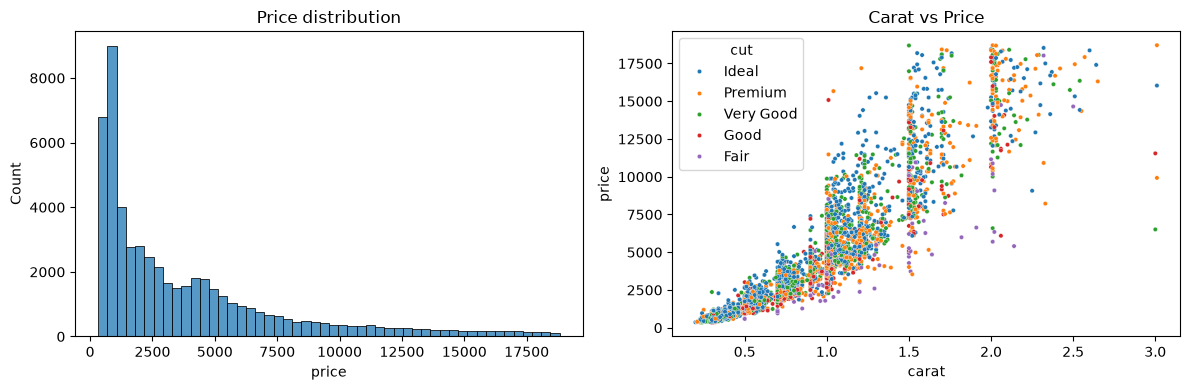

In [4]:
# Diamonds with a zero dimension are invalid records -> remove them
before = len(df)
df = df[(df[["x", "y", "z"]] > 0).all(axis=1)].reset_index(drop=True)
print(f"Removed {before - len(df)} invalid rows. Final shape: {df.shape}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["price"], bins=50, ax=ax[0]); ax[0].set_title("Price distribution")
sns.scatterplot(data=df.sample(5000, random_state=1), x="carat", y="price", hue="cut", ax=ax[1], s=10)
ax[1].set_title("Carat vs Price")
plt.tight_layout(); plt.show()

## Step 4: Preprocessing
Categorical features (cut, color, clarity) are one-hot encoded and numeric features are scaled. Everything lives inside a `Pipeline`, so preprocessing is fitted **only on the training folds** (no data leakage) and the saved model accepts raw input in the web app.

In [5]:
TARGET = "price"
cat_cols = ["cut", "color", "clarity"]
num_cols = ["carat", "depth", "table", "x", "y", "z"]

X = df[cat_cols + num_cols]
y = df[TARGET]

def make_preprocessor():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("num", StandardScaler(), num_cols),
    ])

print("X:", X.shape, "| y:", y.shape)

X: (53920, 9) | y: (53920,)


## Step 5: Define the 5 Algorithms

In [6]:
models = {
    "Ridge Regression":   Ridge(alpha=1.0),
    "ElasticNet":         ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=5000),
    "AdaBoost":           AdaBoostRegressor(n_estimators=100, random_state=RANDOM_STATE),
    "Extra Trees":        ExtraTreesRegressor(n_estimators=100, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1, random_state=RANDOM_STATE),
}
print(list(models))

['Ridge Regression', 'ElasticNet', 'AdaBoost', 'Extra Trees', 'HistGradientBoosting']


## Step 6: 10-Fold Cross-Validation on the Full Dataset
A progress bar shows how many models are done and the estimated time remaining.

In [7]:
kf = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
results, fold_rmse = [], {}

for name, model in tqdm(models.items(), desc="Evaluating models"):
    pipe = Pipeline([("prep", make_preprocessor()), ("model", model)])
    start = time.time()
    cv = cross_validate(
        pipe, X, y, cv=kf,
        scoring={"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"},
        n_jobs=1,
    )
    elapsed = time.time() - start
    rmse = -cv["test_rmse"]
    fold_rmse[name] = rmse
    results.append({
        "Algorithm": name,
        "Mean RMSE": rmse.mean(),
        "Std RMSE": rmse.std(),
        "Mean MAE": (-cv["test_mae"]).mean(),
        "Mean R2": cv["test_r2"].mean(),
        "Time (s)": elapsed,
    })
    print(f"{name:22s} RMSE = {rmse.mean():8.2f} (+/- {rmse.std():.2f})  [{elapsed:.1f}s]")

Evaluating models:   0%|          | 0/5 [00:00<?, ?it/s]

Ridge Regression       RMSE =  1137.13 (+/- 51.12)  [1.2s]
ElasticNet             RMSE =  1145.87 (+/- 43.67)  [14.4s]
AdaBoost               RMSE =  1518.24 (+/- 60.22)  [66.0s]
Extra Trees            RMSE =   530.91 (+/- 20.41)  [65.6s]
HistGradientBoosting   RMSE =   545.18 (+/- 12.82)  [13.1s]


## Step 7: Comparison Table & Charts

In [8]:
results_df = pd.DataFrame(results).sort_values("Mean RMSE").reset_index(drop=True)
results_df.index += 1
display(results_df.round(3))
results_df.to_csv("cv_results.csv")

,Algorithm,Mean RMSE,Std RMSE,Mean MAE,Mean R2,Time (s)
1,Extra Trees,530.907,20.405,263.492,0.982,65.646
2,HistGradientBoosting,545.180,12.820,283.463,0.981,13.093
3,Ridge Regression,1137.126,51.124,735.686,0.919,1.203
4,ElasticNet,1145.867,43.673,746.231,0.917,14.449
5,AdaBoost,1518.237,60.217,1226.931,0.854,65.972


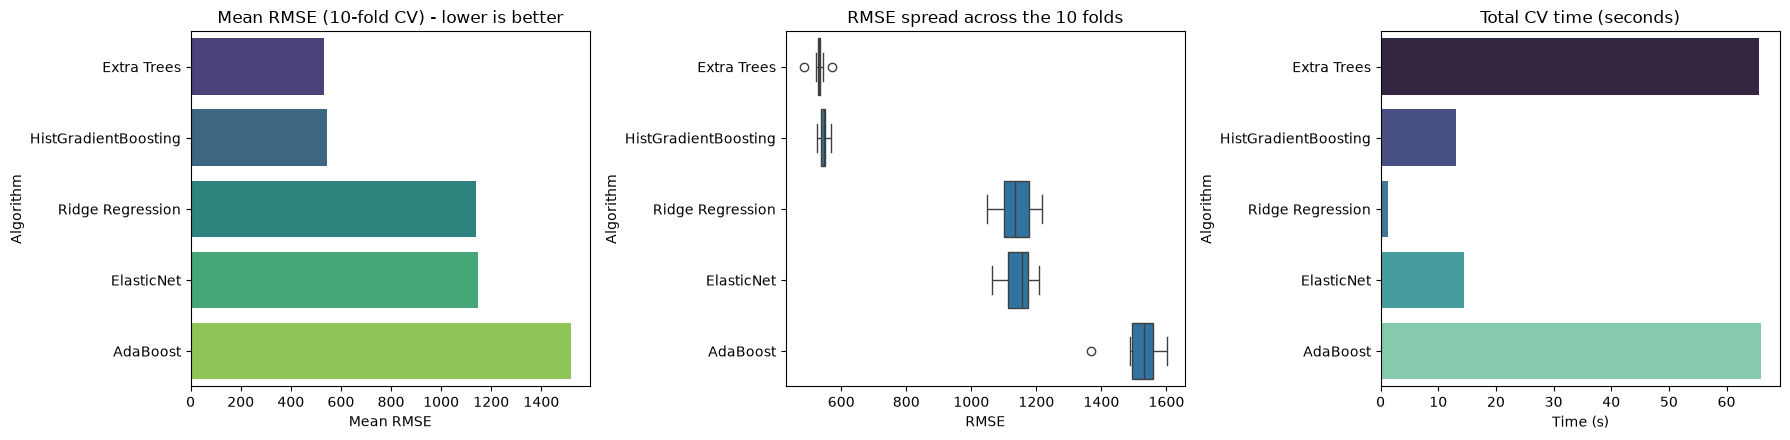

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))

order = results_df["Algorithm"]
sns.barplot(x=results_df["Mean RMSE"], y=order, ax=ax[0], palette="viridis")
ax[0].set_title("Mean RMSE (10-fold CV) - lower is better")

box_df = pd.DataFrame(fold_rmse).melt(var_name="Algorithm", value_name="RMSE")
sns.boxplot(data=box_df, x="RMSE", y="Algorithm", order=order, ax=ax[1])
ax[1].set_title("RMSE spread across the 10 folds")

sns.barplot(x=results_df["Time (s)"], y=order, ax=ax[2], palette="mako")
ax[2].set_title("Total CV time (seconds)")

plt.tight_layout(); plt.savefig("comparison.png", dpi=150); plt.show()

## Step 8: Select the Best Model, Train on All Data & Save

In [11]:
best_name = results_df.iloc[0]["Algorithm"]
print("Best algorithm:", best_name, "| RMSE:", round(results_df.iloc[0]["Mean RMSE"], 2))

final_model = Pipeline([("prep", make_preprocessor()), ("model", models[best_name])])
final_model.fit(X, y)

joblib.dump(final_model, "diamond_price_model.pkl", compress=3)

import os, sklearn
print("scikit-learn version (pin this in requirements.txt):", sklearn.__version__)
print(f"Saved diamond_price_model.pkl ({os.path.getsize('diamond_price_model.pkl')/1e6:.1f} MB)")

# quick sanity check with raw input, exactly as the web app will send it
sample = pd.DataFrame([{"carat": 0.9, "cut": "Ideal", "color": "G", "clarity": "VS2",
                        "depth": 61.5, "table": 56, "x": 6.2, "y": 6.25, "z": 3.8}])
print("Sample prediction: $", round(float(final_model.predict(sample)[0]), 2))

Best algorithm: Extra Trees | RMSE: 530.91
scikit-learn version (pin this in requirements.txt): 1.9.1
Saved diamond_price_model.pkl (86.0 MB)
Sample prediction: $ 4831.34


## Step 9: Deployment (Streamlit Community Cloud)
1. Create a **public GitHub repo** and upload: `app.py`, `requirements.txt`, `diamond_price_model.pkl` (download them from Colab's file panel).
2. Go to **share.streamlit.io** -> *New app* -> select the repo, branch `main`, main file `app.py` -> *Deploy*.
3. Copy the live URL and paste it in the **first cell** of this notebook.
4. Download this notebook (**File -> Download .ipynb**) and upload it with `diamonds.csv` and `diamond_price_model.pkl` to Google Classroom.

If the model file is >100 MB (GitHub limit), reduce `n_estimators`/use a smaller model, or pick the next-best algorithm.

## Conclusion
Write 3-4 lines in your own words: which algorithm had the lowest RMSE, how stable it was across folds, the training-time trade-off, and why you think it won.